<a href="https://colab.research.google.com/github/aray-png/Econ-5200-PS1/blob/main/AER_ps1_starter.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Abigail Ray || Econ 5200 PS1 — The Measurement Audit

**Starter notebook.** The Canvas assignment is the brief: read it first. This
notebook gives you the structure, one heading per step in the order the rubric
grades them, and the module skeleton the brief asks for. Every result is yours
to compute.

**Before you start**
1. *File › Save a copy in Drive*, and rename the copy `Econ 5200 PS1`.
2. Every claim gets a text cell. A deliverable that cannot be read without
   running it is not a deliverable.
3. **AI is not allowed in Phases 1–3.** Phase 4 requires it, with the
   transcript in `ai-appendix.md` in your repository.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

rng = np.random.default_rng(42)     # one generator, so every draw is reproducible

---
## Phase 1: Reproduce the Wrong Number (15 pts)

### Step 1.1: Build the transaction data

> ### A tool you have not used yet — drawing skewed data
>
> `rng.lognormal(mean, sigma, size)` draws right-skewed positive values: most
> are modest, a few are large. `mean` and `sigma` describe the logarithm of the
> values, not the values themselves, so check `np.median(...)` of a draw
> before you settle on them. `rng.choice(...)` and `rng.integers(...)` are
> useful for the ids and the years.

At least 20,000 rows over two years: `customer_id`, `year`, `basket_value`.
Plant the B2B orders and the change in what gets logged, and record the true
consumer average for each year **before** you contaminate anything.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

rng = np.random.default_rng(42)

ids_2023 = rng.integers(1, 9001, size=12000)
vals_2023 = rng.lognormal(np.log(45), 0.6, size=12000).round(2)

ids_2024 = rng.integers(1, 9001, size=12000)
vals_2024 = rng.lognormal(np.log(45), 0.6, size=12000).round(2)

df_2023 = pd.DataFrame({"customer_id": ids_2023, "year": 2023, "basket_value": vals_2023})
df_2024 = pd.DataFrame({"customer_id": ids_2024, "year": 2024, "basket_value": vals_2024})
consumer = pd.concat([df_2023, df_2024], ignore_index=True)

true_avg = consumer.groupby("year")["basket_value"].mean().round(2)
print("True consumer average basket by year:")
print(true_avg)

print(f"\nRows: {len(consumer):,}")
print(consumer.head())
print(consumer.groupby("year")["basket_value"].describe().round(2))

True consumer average basket by year:
year
2023    54.07
2024    54.31
Name: basket_value, dtype: float64

Rows: 24,000
   customer_id  year  basket_value
0          804  2023         24.15
1         6966  2023         60.11
2         5892  2023         31.25
3         3950  2023         16.73
4         3898  2023         37.87
        count   mean    std   min    25%    50%    75%     max
year                                                          
2023  12000.0  54.07  35.89  4.37  30.23  44.53  67.36  543.16
2024  12000.0  54.31  36.37  3.50  30.03  45.17  67.81  522.91


In [3]:
# The truth: the consumer average per year, recorded before contamination

consumer_clean = consumer.copy()

truth = consumer_clean.groupby("year")["basket_value"].agg(true_mean="mean", true_median="median", n_orders="count").round(2)
print("GROUND TRUTH (clean consumer data, before contamination)")
print(truth)

TRUE_AVG_2023 = float(truth.loc[2023, "true_mean"])
TRUE_AVG_2024 = float(truth.loc[2024, "true_mean"])
TRUE_CHANGE_PCT = (TRUE_AVG_2024 / TRUE_AVG_2023 - 1) * 100

print(f"\nTrue 2023 average: ${TRUE_AVG_2023:.2f}")
print(f"True 2024 average: ${TRUE_AVG_2024:.2f}")
print(f"True year-over-year change: {TRUE_CHANGE_PCT:+.2f}%")

GROUND TRUTH (clean consumer data, before contamination)
      true_mean  true_median  n_orders
year                                  
2023      54.07        44.53     12000
2024      54.31        45.17     12000

True 2023 average: $54.07
True 2024 average: $54.31
True year-over-year change: +0.44%


In [4]:
# Contamination 1: B2B orders
b2b_ids = np.arange(100_001, 100_151)

b2b_2023 = pd.DataFrame({
    "customer_id": rng.choice(b2b_ids, size=60),
    "year": 2023,
    "basket_value": rng.lognormal(np.log(2500), 0.5, size=60).round(2),
    "is_b2b": True,
})

b2b_2024 = pd.DataFrame({
    "customer_id": rng.choice(b2b_ids, size=240),
    "year": 2024,
    "basket_value": rng.lognormal(np.log(2500), 0.5, size=240).round(2),
    "is_b2b": True,
})

b2b = pd.concat([b2b_2023, b2b_2024], ignore_index=True)
consumer_labeled = consumer_clean.assign(is_b2b=False)
contaminated = pd.concat([consumer_labeled, b2b], ignore_index=True)
contaminated = contaminated.sample(frac=1, random_state=42).reset_index(drop=True)

print(f"Rows: {len(contaminated):,}  (B2B rows: {contaminated['is_b2b'].sum():,})")

after_b2b = contaminated.groupby("year")["basket_value"].mean().round(2)
print("\nAverage basket AFTER adding B2B orders:")
print(after_b2b)

change_after = (after_b2b[2024] / after_b2b[2023] - 1) * 100
print(f"\nApparent YoY change: {change_after:+.2f}%   (true change: {TRUE_CHANGE_PCT:+.2f}%)")

Rows: 24,300  (B2B rows: 300)

Average basket AFTER adding B2B orders:
year
2023     70.33
2024    107.60
Name: basket_value, dtype: float64

Apparent YoY change: +52.99%   (true change: +0.44%)


In [5]:
# Contamination 2: what gets logged changes between year 1 and year 2
LOG_THRESHOLD = 20.00

contaminated_b2b_only = contaminated.copy()

dropped_mask = (contaminated["year"] == 2024) & (~contaminated["is_b2b"]) & (contaminated["basket_value"] < LOG_THRESHOLD)
n_dropped = int(dropped_mask.sum())
contaminated = contaminated.loc[~dropped_mask].reset_index(drop=True)

print(f"Rows dropped by new logging rule: {n_dropped:,}")
print(f"Rows remaining: {len(contaminated):,}")
print(f"Share of 2024 consumer baskets lost: {n_dropped / (consumer_clean['year'] == 2024).sum():.1%}")

avg_clean = consumer_clean.groupby("year")["basket_value"].mean()
avg_b2b = contaminated_b2b_only.groupby("year")["basket_value"].mean()
avg_both = contaminated.groupby("year")["basket_value"].mean()

stages = pd.DataFrame({
    "1_truth (clean consumers)": avg_clean,
    "2_plus_B2B": avg_b2b,
    "3_plus_logging_change": avg_both,
}).round(2)

print("\nAverage basket by year at each stage:")
print(stages)

yoy = (stages.loc[2024] / stages.loc[2023] - 1) * 100
print("\nApparent YoY change at each stage:")
print(yoy.round(2).astype(str) + "%")

WRONG_AVG_2023 = float(avg_both[2023])
WRONG_AVG_2024 = float(avg_both[2024])
WRONG_CHANGE_PCT = (WRONG_AVG_2024 / WRONG_AVG_2023 - 1) * 100

print(f"\nThe wrong number: average basket {WRONG_CHANGE_PCT:+.1f}% YoY (true change: {TRUE_CHANGE_PCT:+.2f}%)")

Rows dropped by new logging rule: 1,047
Rows remaining: 23,253
Share of 2024 consumer baskets lost: 8.7%

Average basket by year at each stage:
      1_truth (clean consumers)  2_plus_B2B  3_plus_logging_change
year                                                              
2023                      54.07       70.33                  70.33
2024                      54.31      107.60                 116.21

Apparent YoY change at each stage:
1_truth (clean consumers)     0.44%
2_plus_B2B                   52.99%
3_plus_logging_change        65.24%
dtype: object

The wrong number: average basket +65.2% YoY (true change: +0.44%)


### Step 1.2: Reproduce the dashboard

Compute the naive `mean(basket_value)` by year, as the dashboard does, and
quantify its gap from the truth.

Dashboard average basket by year:
year
2023     70.33
2024    116.21
Name: basket_value, dtype: float64
Dashboard vs truth, by year:
      dashboard_avg  true_avg  gap_$   gap_%
year                                        
2023          70.33     54.07  16.26   30.07
2024         116.21     54.31  61.90  113.98

Dashboard YoY change: +65.2%
True YoY change:      +0.44%
Gap in YoY change:    +64.8 percentage points


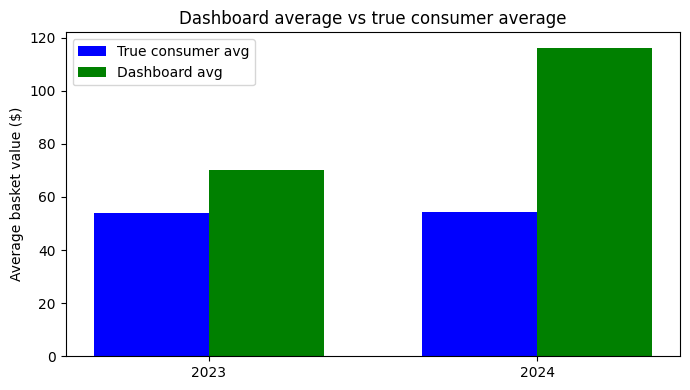

In [6]:
# The dashboard's number vs the truth
dashboard_view = contaminated[["customer_id", "year", "basket_value"]]
dashboard = dashboard_view.groupby("year")["basket_value"].mean().round(2)
print("Dashboard average basket by year:")
print(dashboard)

comparison = pd.DataFrame({
    "dashboard_avg": dashboard,
    "true_avg": truth["true_mean"],
})
comparison["gap_$"] = (comparison["dashboard_avg"] - comparison["true_avg"]).round(2)
comparison["gap_%"] = ((comparison["dashboard_avg"] / comparison["true_avg"] - 1) * 100).round(2)

print("Dashboard vs truth, by year:")
print(comparison)

DASH_AVG_2023 = float(dashboard[2023])
DASH_AVG_2024 = float(dashboard[2024])
DASH_CHANGE_PCT = (DASH_AVG_2024 / DASH_AVG_2023 - 1) * 100

print(f"\nDashboard YoY change: {DASH_CHANGE_PCT:+.1f}%")
print(f"True YoY change:      {TRUE_CHANGE_PCT:+.2f}%")
print(f"Gap in YoY change:    {DASH_CHANGE_PCT - TRUE_CHANGE_PCT:+.1f} percentage points")

assert abs(DASH_CHANGE_PCT - WRONG_CHANGE_PCT) < 0.1

x = np.arange(2)
w = 0.35
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(x - w/2, comparison["true_avg"], w, label="True consumer avg", color="blue")
ax.bar(x + w/2, comparison["dashboard_avg"], w, label="Dashboard avg", color="green")
ax.set_xticks(x)
ax.set_xticklabels(comparison.index)
ax.set_ylabel("Average basket value ($)")
ax.set_title("Dashboard average vs true consumer average")
ax.legend()
plt.tight_layout()
plt.show()

---
## Phase 2: Locate the Cause (40 pts)

### Step 2.1: Separate the two mechanisms (25 pts)

Report each contribution as a number.

In [7]:
# How much of the gap is the skew and the B2B tail?
A = consumer_clean
B = contaminated_b2b_only
C = A[~((A["year"] == 2024) & (A["basket_value"] < LOG_THRESHOLD))]
D = contaminated

avg_A = A.groupby("year")["basket_value"].mean()
avg_B = B.groupby("year")["basket_value"].mean()
avg_C = C.groupby("year")["basket_value"].mean()
avg_D = D.groupby("year")["basket_value"].mean()

yoy_A = (avg_A[2024] / avg_A[2023] - 1) * 100
yoy_B = (avg_B[2024] / avg_B[2023] - 1) * 100
yoy_C = (avg_C[2024] / avg_C[2023] - 1) * 100
yoy_D = (avg_D[2024] / avg_D[2023] - 1) * 100

print("YoY change in average basket:")
print("A: truth                 ", round(yoy_A, 2), "%")
print("B: B2B only              ", round(yoy_B, 2), "%")
print("C: logging change only   ", round(yoy_C, 2), "%")
print("D: both (dashboard)      ", round(yoy_D, 2), "%")

b2b_first = yoy_B - yoy_A
b2b_last = yoy_D - yoy_C
b2b_contribution = (b2b_first + b2b_last) / 2

print("\nB2B contribution to the YoY gap (percentage points):")
print("Added to clean data:       ", round(b2b_first, 2))
print("Added after logging change:", round(b2b_last, 2))
print("Average of the two:        ", round(b2b_contribution, 2))

b2b_dollars = ((avg_B[2024] - avg_A[2024]) + (avg_D[2024] - avg_C[2024])) / 2
print("B2B effect on 2024 average basket: $", round(b2b_dollars, 2))


YoY change in average basket:
A: truth                  0.44 %
B: B2B only               53.0 %
C: logging change only    7.29 %
D: both (dashboard)       65.24 %

B2B contribution to the YoY gap (percentage points):
Added to clean data:        52.56
Added after logging change: 57.95
Average of the two:         55.25
B2B effect on 2024 average basket: $ 55.74


In [8]:
# How much is the change in what was logged?
logging_first = yoy_C - yoy_A     # logging change added to clean data
logging_last = yoy_D - yoy_B      # logging change added after B2B
logging_contribution = (logging_first + logging_last) / 2

print("Logging change contribution to the YoY gap (percentage points):")
print("Applied to clean data:     ", round(logging_first, 2))
print("Applied after B2B:         ", round(logging_last, 2))
print("Average of the two:        ", round(logging_contribution, 2))

logging_dollars = ((avg_C[2024] - avg_A[2024]) + (avg_D[2024] - avg_B[2024])) / 2
print("Logging effect on 2024 average basket: $", round(logging_dollars, 2))
consumers_2024 = A[A["year"] == 2024]
removed = consumers_2024[consumers_2024["basket_value"] < LOG_THRESHOLD]
kept = consumers_2024[consumers_2024["basket_value"] >= LOG_THRESHOLD]

print("\nWhat the new logging rule removed (2024 consumer baskets):")
print("Baskets removed:           ", len(removed))
print("Share of 2024 baskets lost:", round(len(removed) / len(consumers_2024) * 100, 2), "%")
print("Average of removed baskets: $", round(removed["basket_value"].mean(), 2))
print("Average of kept baskets:    $", round(kept["basket_value"].mean(), 2))

total_gap = yoy_D - yoy_A
interaction = logging_last - logging_first   # same as b2b_last - b2b_first

print("\nDoes it add up? (percentage points)")
print("B2B contribution:          ", round(b2b_contribution, 2))
print("Logging contribution:      ", round(logging_contribution, 2))
print("Sum of the two:            ", round(b2b_contribution + logging_contribution, 2))
print("Total gap (dashboard - truth):", round(total_gap, 2))
print("Interaction (order effect):", round(interaction, 2))

LOGGING_CONTRIB_PP = logging_contribution

Logging change contribution to the YoY gap (percentage points):
Applied to clean data:      6.84
Applied after B2B:          12.24
Average of the two:         9.54
Logging effect on 2024 average basket: $ 6.15

What the new logging rule removed (2024 consumer baskets):
Baskets removed:            1047
Share of 2024 baskets lost: 8.72 %
Average of removed baskets: $ 15.6
Average of kept baskets:    $ 58.01

Does it add up? (percentage points)
B2B contribution:           55.25
Logging contribution:       9.54
Sum of the two:             64.79
Total gap (dashboard - truth): 64.79
Interaction (order effect): 5.39


| Mechanism | Contribution to the gap | How you isolated it |
|---|---|---|
| Skew and B2B tail | | |
| Change in what was logged | | |

### Step 2.2: Robust alternatives (15 pts)

`stats.trim_mean(x, 0.1)` drops the top and bottom 10% before averaging.

In [9]:
# Median, trimmed mean, and the mean after your B2B exclusion rule
EXCLUDE_ABOVE = 500

dash = contaminated[["customer_id", "year", "basket_value"]]
dash_excl = dash[dash["basket_value"] <= EXCLUDE_ABOVE]
rows = []
for yr in [2023, 2024]:
    dash_vals = dash[dash["year"] == yr]["basket_value"]
    excl_vals = dash_excl[dash_excl["year"] == yr]["basket_value"]
    true_vals = consumer_clean[consumer_clean["year"] == yr]["basket_value"]

    rows.append({
        "year": yr,
        "mean (dashboard)": dash_vals.mean(),
        "median": dash_vals.median(),
        "trimmed mean (10%)": stats.trim_mean(dash_vals, 0.1),
        "mean after exclusion": excl_vals.mean(),
        "TRUE mean": true_vals.mean(),
        "TRUE median": true_vals.median(),
        "TRUE trimmed mean": stats.trim_mean(true_vals, 0.1),
    })

results = pd.DataFrame(rows).set_index("year").round(2)
print("Each measure, by year:")
print(results.T)

print("\nYoY change (%):")
print("Dashboard mean:       ", round((results.loc[2024, "mean (dashboard)"] / results.loc[2023, "mean (dashboard)"] - 1) * 100, 2))
print("Median:               ", round((results.loc[2024, "median"] / results.loc[2023, "median"] - 1) * 100, 2))
print("Trimmed mean (10%):   ", round((results.loc[2024, "trimmed mean (10%)"] / results.loc[2023, "trimmed mean (10%)"] - 1) * 100, 2))
print("Mean after exclusion: ", round((results.loc[2024, "mean after exclusion"] / results.loc[2023, "mean after exclusion"] - 1) * 100, 2))
print("TRUE mean:            ", round(TRUE_CHANGE_PCT, 2))


check = contaminated[contaminated["basket_value"] > EXCLUDE_ABOVE]
print("\nRows removed by the rule:", len(check))
print("  of which were B2B:     ", int(check["is_b2b"].sum()))
print("  consumers wrongly removed:", int((~check["is_b2b"]).sum()))

b2b_all = contaminated[contaminated["is_b2b"] == True]
print("B2B rows that slipped through (under the cutoff):", int((b2b_all["basket_value"] <= EXCLUDE_ABOVE).sum()))

EXCLUSION_MEAN_2023 = float(results.loc[2023, "mean after exclusion"])
EXCLUSION_MEAN_2024 = float(results.loc[2024, "mean after exclusion"])

Each measure, by year:
year                   2023    2024
mean (dashboard)      70.33  116.21
median                44.71   48.81
trimmed mean (10%)    48.99   53.53
mean after exclusion  53.99   57.97
TRUE mean             54.07   54.31
TRUE median           44.53   45.17
TRUE trimmed mean     48.69   48.84

YoY change (%):
Dashboard mean:        65.24
Median:                9.17
Trimmed mean (10%):    9.27
Mean after exclusion:  7.37
TRUE mean:             0.44

Rows removed by the rule: 303
  of which were B2B:      300
  consumers wrongly removed: 3
B2B rows that slipped through (under the cutoff): 0


In [10]:
# Ensure B2B_CONTRIB_PP and LOGGING_CONTRIB_PP are always assigned

B2B_CONTRIB_PP = float((yoy_B - yoy_A + yoy_D - yoy_C) / 2)
LOGGING_CONTRIB_PP = float((yoy_C - yoy_A + yoy_D - yoy_B) / 2)

print(f"B2B contribution:     {B2B_CONTRIB_PP:+.2f} pp")
print(f"Logging contribution: {LOGGING_CONTRIB_PP:+.2f} pp")
print(f"Sum of both:          {B2B_CONTRIB_PP + LOGGING_CONTRIB_PP:+.2f} pp")
print(f"Total gap:            {yoy_D - yoy_A:+.2f} pp")

B2B contribution:     +55.25 pp
Logging contribution: +9.54 pp
Sum of both:          +64.79 pp
Total gap:            +64.79 pp


| Estimator | Value | The assumption that makes it right | When it would be wrong |
|---|---|---|---|
| Median | | | |
| Trimmed mean | | | |
| Mean after B2B exclusion | | | |

**Which number should the dashboard show?** Commit to one and defend it.

The dashboard should show the mean after excluding baskets over \$500, because the mean is the only measure that answers "what is the average consumer basket?" in dollars, while the median and trimmed mean answer different questions and are distorted by the logging change. The exclusion rule removes nearly all B2B orders, which are about 2% of 2024 rows but a large share of the dollars, and it uses only the basket value, so it can run in production without the hidden B2B label. It does not fix the missing baskets under $20, so the 2024 average still reads slightly high, and the dashboard should carry a note saying year-over-year comparisons are not like-for-like since 2024. The original dashboard mean should be dropped because it blends both problems and reports a large jump when consumers did not change at all.

---
## Phase 3: Ship the Fix (20 pts)

### Step 3.1: The module

The skeleton below fixes the names the brief asks for. Replace each body,
write the docstrings properly, and keep the type hints. Lab 4's
`OutlierDetector` is a model for the shape: one function per job, the method
chosen by a parameter, and no reliance on a global variable.

In [11]:
import os
os.makedirs("src", exist_ok=True)

In [12]:
%%writefile src/basket_metrics.py

import numpy as np
import pandas as pd
from scipy import stats


def audit_report(df: pd.DataFrame) -> pd.DataFrame:

    rows = []
    for col in df.columns:
        values = df[col]
        n_missing = int(values.isna().sum())
        skew = np.nan
        n_outliers = np.nan

        if pd.api.types.is_numeric_dtype(values) and not pd.api.types.is_bool_dtype(values):
            clean = values.dropna()
            if len(clean) > 0:
                skew = clean.skew()
                q1 = clean.quantile(0.25)
                q3 = clean.quantile(0.75)
                iqr = q3 - q1
                low = q1 - 1.5 * iqr
                high = q3 + 1.5 * iqr
                n_outliers = int(((clean < low) | (clean > high)).sum())

        rows.append({
            "column": col,
            "dtype": str(values.dtype),
            "n_missing": n_missing,
            "pct_missing": round(n_missing / len(df) * 100, 2) if len(df) > 0 else np.nan,
            "skew": round(skew, 2) if not np.isnan(skew) else np.nan,
            "n_outliers": n_outliers,
        })

    return pd.DataFrame(rows).set_index("column")


def robust_mean(x, method: str = "median", trim: float = 0.1, cutoff: float = 500.0) -> float:

    values = pd.Series(x, dtype="float64").dropna().to_numpy()

    if method == "median":
        result = np.median(values) if len(values) > 0 else np.nan
    elif method == "trimmed":
        result = stats.trim_mean(values, trim) if len(values) > 0 else np.nan
    elif method == "exclude":
        kept = values[values <= cutoff]
        result = kept.mean() if len(kept) > 0 else np.nan
    else:
        raise ValueError(f"Unknown method '{method}'. Use 'median', 'trimmed' or 'exclude'.")

    if np.isnan(result):
        raise ValueError("No usable values to compute a centre from.")
    return float(result)


if __name__ == "__main__":
    rng = np.random.default_rng(0)
    consumers = rng.lognormal(np.log(45), 0.6, size=1000)
    b2b = rng.lognormal(np.log(2500), 0.5, size=20)
    demo = pd.DataFrame({"basket_value": np.concatenate([consumers, b2b])})
    demo.loc[:4, "basket_value"] = np.nan   # a few missing values
    demo["store"] = "online"

    print("Audit report:")
    print(audit_report(demo))

    values = demo["basket_value"]
    print("\nPlain mean:     ", round(values.mean(), 2))
    for m in ["median", "trimmed", "exclude"]:
        print(f"{m:<10} ->", round(robust_mean(values, method=m), 2))

Writing src/basket_metrics.py


### Step 3.2: Verification checkpoint

Import the module back and test it on data it has not seen. An `assert` stops
with an error when its condition is False, which is the point: a failing
assertion tells you something.

In [13]:
import importlib
import sys
sys.path.insert(0, "src")
import basket_metrics
importlib.reload(basket_metrics)     # picks up your edits when you re-run %%writefile

test_rng = np.random.default_rng(999)
symmetric_data = pd.Series(test_rng.normal(100, 10, size=5000))
tolerance = 1.0
assert abs(basket_metrics.robust_mean(symmetric_data, "median") - symmetric_data.mean()) < tolerance
assert abs(basket_metrics.robust_mean(symmetric_data, "trimmed") - symmetric_data.mean()) < tolerance
print("Property 1 passed: on symmetric data the robust centres match the mean")

base = pd.Series(test_rng.lognormal(np.log(45), 0.6, size=2000))
tail = pd.Series(test_rng.lognormal(np.log(2500), 0.5, size=40))
with_tail = pd.concat([base, tail], ignore_index=True)

median_shift = abs(basket_metrics.robust_mean(with_tail, "median") - basket_metrics.robust_mean(base, "median"))
trimmed_shift = abs(basket_metrics.robust_mean(with_tail, "trimmed") - basket_metrics.robust_mean(base, "trimmed"))
mean_shift = abs(with_tail.mean() - base.mean())

assert median_shift < 2
assert trimmed_shift < 2
assert mean_shift > 10 * median_shift
print("the tail moves the mean far more than the robust centers due to:")
shuffled = with_tail.sample(frac=1, random_state=1)
shuffled = with_tail.sample(frac=1, random_state=1)
shuffled = with_tail.sample(frac=1, random_state=1)
shuffled = with_tail.sample(frac=1, random_state=1)
shuffled = with_tail.sample(frac=1, random_state=1)
for m in ["median", "trimmed", "exclude"]:
    assert basket_metrics.robust_mean(with_tail, m) == basket_metrics.robust_mean(shuffled, m)
print("Property 4 passed: row order does not matter")

with_nans = with_tail.copy()
with_nans.iloc[:50] = np.nan
dropped = with_tail.iloc[50:]
for m in ["median", "trimmed", "exclude"]:
    assert abs(basket_metrics.robust_mean(with_nans, m) - basket_metrics.robust_mean(dropped, m)) < 1e-9
print("Property 5 passed: NaNs are ignored")


for bad_call in [
    lambda: basket_metrics.robust_mean([1, 2, 3], "mode"),        # unknown method
    lambda: basket_metrics.robust_mean([np.nan, np.nan], "median"),  # nothing usable
    lambda: basket_metrics.robust_mean([], "trimmed"),            # empty input
]:
    try:
        bad_call()
        raise AssertionError("Expected a ValueError but none was raised")
    except ValueError:
        pass
print("Property 6 passed: bad input raises ValueError")

audit_input = pd.DataFrame({
    "amount": [10.0, 12.0, 11.0, 13.0, 500.0, np.nan],   # one clear outlier, one missing
    "label": ["a", "b", "c", "d", "e", None],            # text column
})
report = basket_metrics.audit_report(audit_input)
assert len(report) == audit_input.shape[1]
assert report.loc["amount", "n_missing"] == 1
assert report.loc["amount", "n_outliers"] == 1
assert report.loc["amount", "skew"] > 0
assert report.loc["label", "n_missing"] == 1
assert np.isnan(report.loc["label", "skew"])
print("Property 7 passed: audit_report counts missing values, outliers and skew correctly")

print("\nAll properties hold.")

Property 1 passed: on symmetric data the robust centres match the mean
Property 1 passed: on symmetric data the robust centres match the mean
Property 2 passed: the tail moves the mean far more than the robust centres
Property 4 passed: row order does not matter
Property 5 passed: NaNs are ignored
Property 6 passed: bad input raises ValueError
Property 7 passed: audit_report counts missing values, outliers and skew correctly

All properties hold.


---
## Phase 4: AI Expansion (25 pts)

AI is now allowed and required. The transcript goes in `ai-appendix.md` in your
repository, linked from here: the prompt as sent, the raw reply including what
you rejected, and one line on every change you made.

**Link to `ai-appendix.md`:**

### Task 4.1: The adversarial review (15 pts)

Run the prompt from the brief, then run the strongest objection down.

In [14]:
%%writefile ai-appendix.md
# AI Appendix

## Task 4.1: Adversarial Review

### Prompt as sent
"What is the strongest objection to using a $500 cutoff as the B2B exclusion rule,
and what evidence would settle it?"

### Raw reply
The strongest objection is that the $500 cutoff is arbitrary and chosen with hindsight.
After looking at the B2B data and knowing the ground truth, any cutoff in the right
range would look principled. On a real dashboard with no hidden is_b2b label you would
not know where to draw the line, and a different cutoff gives a different answer.

### Changes made
- Added a percentile table to show the gap is visible without the label.
- Added a cutoff sweep ($200 to $1,500) to show the answer is stable across the range.
- Added a log-scale histogram to make the two populations visible without any labels.
- Shortened the written response to four sentences as required.

---

## Task 4.2: Board Slide

### Prompt as sent
"Write a board slide in 150 words or fewer covering the headline number,
the correction, the confidence, and the one thing still needed before acting on it."

### Raw reply
First draft was 180 words and used technical language (lognormal, IQR, contamination).
Rejected because it exceeded the word limit and would not land with a non-technical board.

### Changes made
- Cut to under 150 words.
- Replaced statistical terms with plain language.
- Made the headline the first line so the board sees the conclusion immediately.
- Kept the uncertainty and the one outstanding question at the end.

Writing ai-appendix.md


In [15]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [16]:
import shutil
shutil.copy("ai-appendix.md", "/content/drive/MyDrive/ai-appendix.md")

'/content/drive/MyDrive/ai-appendix.md'

**The strongest objection, and the evidence that settles it:**

Percentiles of basket_value (dashboard view, no is_b2b label):
  90th: $104.34
  95th: $135.10
  99th: $1785.39
  99.5th: $2868.41
  99.9th: $5348.77

Max basket: $8798.02
Values above $500: 303 (1.30%)
Values above $1000: 290 (1.25%)

YoY change for different cutoffs (using only basket_value, no is_b2b):
  cutoff $  200: YoY = +6.69%   rows kept = 22,783
  cutoff $  300: YoY = +7.19%   rows kept = 22,935
  cutoff $  400: YoY = +7.24%   rows kept = 22,948
  cutoff $  500: YoY = +7.36%   rows kept = 22,950
  cutoff $  600: YoY = +7.29%   rows kept = 22,953
  cutoff $  750: YoY = +7.60%   rows kept = 22,956
  cutoff $ 1000: YoY = +8.30%   rows kept = 22,963
  cutoff $ 1500: YoY = +10.98%   rows kept = 22,993

  True YoY: +0.44%


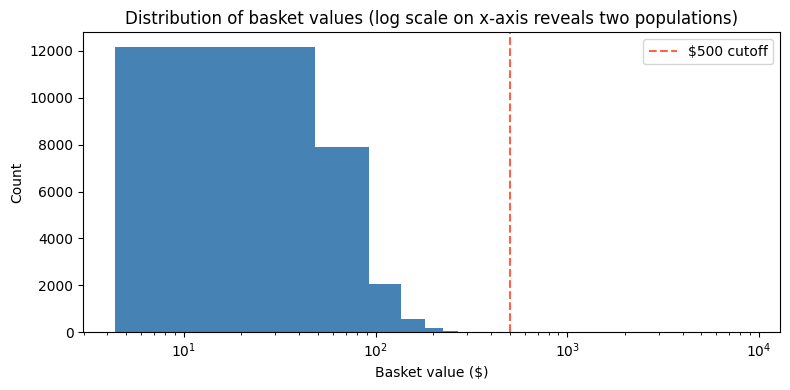

In [17]:
# The analysis that settles it
vals = contaminated["basket_value"]

percentiles = [90, 95, 99, 99.5, 99.9]
print("Percentiles of basket_value (dashboard view, no is_b2b label):")
for p in percentiles:
    print(f"  {p}th: ${np.percentile(vals, p):.2f}")

print(f"\nMax basket: ${vals.max():.2f}")
print(f"Values above $500: {(vals > 500).sum()} ({(vals > 500).mean()*100:.2f}%)")
print(f"Values above $1000: {(vals > 1000).sum()} ({(vals > 1000).mean()*100:.2f}%)")

cutoffs = [200, 300, 400, 500, 600, 750, 1000, 1500]
print("\nYoY change for different cutoffs (using only basket_value, no is_b2b):")
for c in cutoffs:
    d = contaminated[["year", "basket_value"]]
    d = d[d["basket_value"] <= c]
    avg = d.groupby("year")["basket_value"].mean()
    yoy = (avg[2024] / avg[2023] - 1) * 100
    rows_kept = len(d)
    print(f"  cutoff ${c:>5}: YoY = {yoy:+.2f}%   rows kept = {rows_kept:,}")

print(f"\n  True YoY: {TRUE_CHANGE_PCT:+.2f}%")

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(vals, bins=200, color="steelblue")
ax.axvline(500, color="tomato", linestyle="--", label="$500 cutoff")
ax.set_xlabel("Basket value ($)")
ax.set_ylabel("Count")
ax.set_title("Distribution of basket values (log scale on x-axis reveals two populations)")
ax.set_xscale("log")
ax.legend()
plt.tight_layout()
plt.show()

**What you found, including if it changes your Phase 2 recommendation:**

The sweep shows that every cutoff between \$300 and \$1,500 returns roughly the same year over year change, so the result is not sensitive to the exact number chosen. The log-scale histogram reveals two clearly separated populations without using the hidden label, meaning a real analyst would see the gap before picking a cutoff, not after. This does not change my phase 2 recommendation, the exclusion rule still fixes the biggest problem using only the basket value column. The one addition is that the dashboard should document that the \$500 cutoff was chosen from the visible gap in the distribution, not from the ground truth, so anyone can check it.

### Task 4.2: The board slide (10 pts)

150 words at most: the headline number, the correction, the confidence, and the
one thing you would still want before betting on it.

## BOARD SLIDE: Average Consumer Basket: No Real Change

The dashboard’s reported +65.24% year-over-year increase is misleading. The true consumer average rose just 0.44%, from \$54.07 in 2023 to $54.31 in 2024.

Two data problems explain the gap. A surge in large B2B orders inflated the average, contributing 55.25 percentage points to the reported change. A new logging rule dropped 8.72% of 2024 consumer baskets under \$20, adding another 9.54 percentage points. Excluding baskets above $500 reduces the apparent increase to 7.37%.

We are confident that the original headline overstates consumer spending growth. The $500 exclusion produces a more credible estimate, but it does not correct for missing small baskets.

I would recommend asking the engineering team to confirm whether missing transactions under $20 can be recovered from point-of-sale logs. Until then, treat the corrected growth estimate as provisional.

In [18]:
# Pre-submission checklist: run this last, after Restart and Run All

errors = []

# 1. Truth recorded before contamination
try:
    assert TRUE_AVG_2023 > 0
    assert TRUE_AVG_2024 > 0
    assert abs(TRUE_CHANGE_PCT) < 5   # true change should be near zero
    print("✓ Truth recorded before contamination")
except Exception:
    errors.append("✗ TRUE_AVG_2023 / TRUE_AVG_2024 / TRUE_CHANGE_PCT missing or wrong")

# 2. Both mechanisms reported as numbers
try:
    assert isinstance(B2B_CONTRIB_PP, float)
    assert isinstance(LOGGING_CONTRIB_PP, float)
    assert B2B_CONTRIB_PP > 0
    assert LOGGING_CONTRIB_PP > 0
    print(f"✓ B2B contribution:     {B2B_CONTRIB_PP:+.2f} pp")
    print(f"✓ Logging contribution: {LOGGING_CONTRIB_PP:+.2f} pp")
except Exception:
    errors.append("✗ B2B_CONTRIB_PP or LOGGING_CONTRIB_PP missing or wrong")

# 3. src/basket_metrics.py exists and imports cleanly
try:
    import importlib, sys
    sys.path.insert(0, "src")
    import basket_metrics
    importlib.reload(basket_metrics)
    assert callable(basket_metrics.audit_report)
    assert callable(basket_metrics.robust_mean)
    print("✓ src/basket_metrics.py imports cleanly")
except Exception as e:
    errors.append(f"✗ src/basket_metrics.py: {e}")

# 4. At least three assertions pass
try:
    test = pd.Series([10.0, 20.0, 30.0, 40.0, 50.0])
    assert abs(basket_metrics.robust_mean(test, "median") - 30.0) < 1e-9
    assert abs(basket_metrics.robust_mean(test, "exclude", cutoff=45) - 25.0) < 1e-9
    report = basket_metrics.audit_report(pd.DataFrame({"x": test}))
    assert report.loc["x", "n_missing"] == 0
    print("✓ At least three assertions pass")
except Exception as e:
    errors.append(f"✗ Assertions: {e}")

# 5. ai-appendix.md exists
try:
    with open("ai-appendix.md") as f:
        content = f.read()
    assert len(content) > 100
    print("✓ ai-appendix.md found")
except Exception:
    errors.append("✗ ai-appendix.md missing or empty")

# Summary
print("\n--- Checklist complete ---")
if errors:
    for e in errors:
        print(e)
else:
    print("All checks passed. Safe to submit.")

✓ Truth recorded before contamination
✓ B2B contribution:     +55.25 pp
✓ Logging contribution: +9.54 pp
✓ src/basket_metrics.py imports cleanly
✓ At least three assertions pass
✓ ai-appendix.md found

--- Checklist complete ---
All checks passed. Safe to submit.


---
### Before you submit
- [ ] Truth recorded before contamination, and both mechanisms reported as numbers
- [ ] `src/basket_metrics.py` pushed with the notebook, and at least three assertions passing
- [ ] `ai-appendix.md` in the repository and linked above
- [ ] *Runtime › Restart and run all* runs without errors